In [31]:
from langgraph.graph import StateGraph , START,END
from pydantic import BaseModel , Field

In [32]:
class state(BaseModel):
    input_text: str
    extracted_info: str = ""
    summary: str = ""
    extract_keywords: list[str] = Field(default_factory=list)
    final_report: str = ""

In [33]:
from langchain_ollama import OllamaLLM
def extract_info(state:state)->state:
    inp_text = state.input_text
    llm = OllamaLLM(model="llama3.2:1b")
    response = llm.invoke(f"You are extract information agent , extract the relevent info from the text : {inp_text}")
   
#     print(response)
    return {
         "extracted_info": response
    }

In [34]:
def summary(state:state)->state:
    from langchain_ollama import OllamaLLM
    inp_text = state.extracted_info
    llm = OllamaLLM(model="llama3.2:1b")
    response = llm.invoke(f"You are Summarization agent , Give summary from the text : {inp_text}")
   
    # print(response)
    return {
        "summary": response    }

In [35]:
from langchain_ollama import OllamaLLM
from langchain_groq import ChatGroq
from dotenv import load_dotenv
load_dotenv()
class keywords(BaseModel):
    keyword:list = Field(description="List of keywords")

def extract_keyword(state):
    inp_text = state.summary
    llm = ChatGroq(model="openai/gpt-oss-120b").with_structured_output(keywords)

    response = llm.invoke(f"You are extract keyword agent , extract the relevent keywords from the text : {inp_text}")
    

    return {
        "extract_keywords": response.keyword
        }

In [36]:
def final_report(state) -> dict:
    separator = "=" * 50

    final = f"""
{separator} 
            AI TEXT ANALYSIS REPORT
{separator}

1. EXTRACTED INFORMATION
{state.extracted_info}

{separator}

2. SUMMARY
{state.summary}

{separator}

3. KEYWORDS
{", ".join(state.extract_keywords)}

{separator}
                END OF REPORT
{separator}
                """
    # print(final)
    return {"final_report": final.strip()}

In [37]:
graph = StateGraph(state)

In [38]:
graph.add_node("Extract Info",extract_info)
graph.add_node("Summary",summary)
graph.add_node("Extract keyword",extract_keyword)
graph.add_node("Final Report",final_report)


In [39]:
graph.add_edge(START,"Extract Info")
graph.add_edge("Extract Info","Summary")
graph.add_edge("Summary","Extract keyword")
graph.add_edge("Extract keyword","Final Report")
graph.add_edge("Final Report",END)

In [40]:
print(graph.nodes.keys())

dict_keys(['Extract Info', 'Summary', 'Extract keyword', 'Final Report'])


In [41]:
workflow = graph.compile()

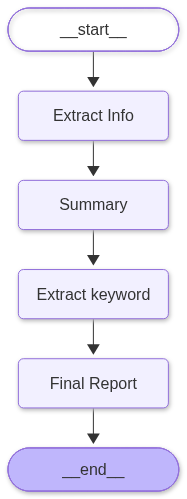

In [42]:
workflow

In [43]:
initial_state = {
    "input_text": "OpenAI has announced a new AI model designed to improve reasoning capabilities. The model can solve complex mathematical problems, write code, and assist researchers. The company claims that the new model is more efficient than previous generations."
}
r = workflow.invoke(initial_state)

In [44]:

print(r["final_report"])

            AI TEXT ANALYSIS REPORT

1. EXTRACTED INFORMATION
Here's the relevant information extracted from the text:

- OpenAI has announced a new AI model.
- The model is designed to improve reasoning capabilities.
- The model can solve complex mathematical problems.
- The model can write code.
- The model is designed to assist researchers.
- The model is more efficient than previous generations.


2. SUMMARY
Here's a summary of the text:

OpenAI has launched a new AI model that aims to improve reasoning capabilities. The model is capable of solving complex mathematical problems and writing code. It is designed to assist researchers and is more efficient than previous AI models.


3. KEYWORDS
OpenAI, AI model, reasoning capabilities, complex mathematical problems, code writing, assist researchers, efficiency, previous AI models

                END OF REPORT
